<a href="https://colab.research.google.com/github/Luis03-coder/ContactosApp1/blob/master/PIA_Ventas_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de ventas internacionales
## Producto Integrador de Aprendizaje



## 1 Importar las bibliotecas

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
salida = Path('resultados_pia')
salida.mkdir(exist_ok=True)


## 2 Cargar el DataFrame

In [ ]:

df = pd.read_csv("sales.csv", dtype={'Order ID': 'string'})

display(df.head())


,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit
0,Middle East and North Africa,Azerbaijan,Snacks,Online,C,10/8/2014,535113847,10/23/2014,934,152.58,97.44,142509.72,91008.96,51500.76
1,Central America and the Caribbean,Panama,Cosmetics,Offline,L,2/22/2015,874708545,2/27/2015,4551,437.20,263.33,1989697.20,1198414.83,791282.37
2,Sub-Saharan Africa,Sao Tome and Principe,Fruits,Offline,M,12/9/2015,854349935,1/18/2016,9986,9.33,6.92,93169.38,69103.12,24066.26
3,Sub-Saharan Africa,Sao Tome and Principe,Personal Care,Online,M,9/17/2014,892836844,10/12/2014,9118,81.73,56.67,745214.14,516717.06,228497.08
4,Central America and the Caribbean,Belize,Household,Offline,H,2/4/2010,129280602,3/5/2010,5858,668.27,502.54,3914725.66,2943879.32,970846.34


## 3 Explorar y validar los datos

In [ ]:
df.head().to_csv(salida / 'primeras_filas.csv', index=False)
df.tail().to_csv(salida / 'ultimas_filas.csv', index=False)
calidad = pd.DataFrame({'tipo_original': df.dtypes.astype(str),
                        'faltantes': df.isna().sum()})
calidad.to_csv(salida / 'calidad.csv')
print('Dimensiones:', df.shape)
print('Duplicados completos:', df.duplicated().sum())
print('ID repetidos:', df['Order ID'].duplicated().sum())
for col in ['Order Date', 'Ship Date']:
    df[col] = pd.to_datetime(df[col], format='%m/%d/%Y', errors='raise')

assert not df.isna().any().any(), 'Revisar valores faltantes'
assert not df.duplicated().any(), 'Revisar duplicados'
assert not df['Order ID'].duplicated().any(), 'Revisar identificadores'
for total, esperado in [
    ('Total Revenue', df['Units Sold'] * df['Unit Price']),
    ('Total Cost', df['Units Sold'] * df['Unit Cost']),
    ('Total Profit', df['Total Revenue'] - df['Total Cost'])]:
    assert np.allclose(df[total], esperado, atol=0.01, rtol=0)
assert (df['Ship Date'] >= df['Order Date']).all()
assert (df[['Units Sold', 'Unit Price', 'Unit Cost']] > 0).all().all()

print('Primeras filas'); display(df.head())
print('Últimas filas'); display(df.tail())
display(calidad)
print('Validaciones completadas correctamente.')


Dimensiones: (100000, 14)
Duplicados completos: 0
ID repetidos: 0
Primeras filas


,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit
0,Middle East and North Africa,Azerbaijan,Snacks,Online,C,2014-10-08,535113847,2014-10-23,934,152.58,97.44,142509.72,91008.96,51500.76
1,Central America and the Caribbean,Panama,Cosmetics,Offline,L,2015-02-22,874708545,2015-02-27,4551,437.20,263.33,1989697.20,1198414.83,791282.37
2,Sub-Saharan Africa,Sao Tome and Principe,Fruits,Offline,M,2015-12-09,854349935,2016-01-18,9986,9.33,6.92,93169.38,69103.12,24066.26
3,Sub-Saharan Africa,Sao Tome and Principe,Personal Care,Online,M,2014-09-17,892836844,2014-10-12,9118,81.73,56.67,745214.14,516717.06,228497.08
4,Central America and the Caribbean,Belize,Household,Offline,H,2010-02-04,129280602,2010-03-05,5858,668.27,502.54,3914725.66,2943879.32,970846.34


Últimas filas


,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit
99995,Sub-Saharan Africa,Niger,Cereal,Offline,L,2012-08-26,836322486,2012-09-11,5263,205.70,117.11,1082599.10,616349.93,466249.17
99996,Europe,Poland,Meat,Offline,C,2013-12-03,110449349,2013-12-10,3272,421.89,364.69,1380424.08,1193265.68,187158.40
99997,Sub-Saharan Africa,Comoros,Clothes,Online,M,2013-08-07,193128764,2013-08-31,9948,109.28,35.84,1087117.44,356536.32,730581.12
99998,Middle East and North Africa,Kuwait,Cosmetics,Online,L,2011-06-28,701597058,2011-07-03,7015,437.20,263.33,3066958.00,1847259.95,1219698.05
99999,Sub-Saharan Africa,Tanzania,Cosmetics,Offline,C,2012-04-03,423403060,2012-04-30,3229,437.20,263.33,1411718.80,850292.57,561426.23


,tipo_original,faltantes
Region,object,0
Country,object,0
Item Type,object,0
Sales Channel,object,0
Order Priority,object,0
Order Date,object,0
Order ID,string,0
Ship Date,object,0
Units Sold,int64,0
Unit Price,float64,0


Validaciones completadas correctamente.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 4 Crear Series y DataFrames

In [ ]:
ingresos = df['Total Revenue'].copy()
ventas = df[['Country', 'Item Type', 'Units Sold', 'Total Revenue']].copy()
df['Margen_pct'] = df['Total Profit'] / ingresos * 100
df['Dias_envio'] = (df['Ship Date'] - df['Order Date']).dt.days
ventas.head().to_csv(salida / 'dataframe_ejemplo.csv', index=False)
ingresos.head().to_csv(salida / 'series_ejemplo.csv', index=False)

display(ingresos.head()); display(ventas.head())


,Total Revenue
0,142509.72
1,1989697.20
2,93169.38
3,745214.14
4,3914725.66


,Country,Item Type,Units Sold,Total Revenue
0,Azerbaijan,Snacks,934,142509.72
1,Panama,Cosmetics,4551,1989697.20
2,Sao Tome and Principe,Fruits,9986,93169.38
3,Sao Tome and Principe,Personal Care,9118,745214.14
4,Belize,Household,5858,3914725.66


### 5 Filtrar por país y categoría

In [ ]:
filtro = df.loc[(df['Country'] == 'Mexico') &
                (df['Item Type'] == 'Cosmetics')]
filtro.to_csv(salida / 'mexico_cosmeticos.csv', index=False)

print('Pedidos de cosméticos en México:', len(filtro)); display(filtro.head())


Pedidos de cosméticos en México: 55


,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,Margen_pct,Dias_envio
5269,North America,Mexico,Cosmetics,Offline,M,2016-09-04,428562343,2016-09-17,9976,437.2,263.33,4361507.2,2626980.08,1734527.12,39.768984,13
5403,North America,Mexico,Cosmetics,Offline,H,2010-11-06,635767066,2010-12-16,6458,437.2,263.33,2823437.6,1700585.14,1122852.46,39.768984,40
8011,North America,Mexico,Cosmetics,Offline,C,2010-01-12,356295478,2010-02-13,4604,437.2,263.33,2012868.8,1212371.32,800497.48,39.768984,32
8571,North America,Mexico,Cosmetics,Offline,C,2016-03-12,290398108,2016-04-19,4108,437.2,263.33,1796017.6,1081759.64,714257.96,39.768984,38
8628,North America,Mexico,Cosmetics,Offline,M,2014-03-12,291624200,2014-04-12,6936,437.2,263.33,3032419.2,1826456.88,1205962.32,39.768984,31


## 6 Aplicar un filtro booleano

In [ ]:
altas = df.loc[(df['Total Profit'] > 500000) &
              (df['Sales Channel'] == 'Online')]
altas.to_csv(salida / 'online_ganancia_alta.csv', index=False)

print('Pedidos Online con ganancia mayor a 500000:', len(altas)); display(altas.head())


Pedidos Online con ganancia mayor a 500000: 15395


,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,Margen_pct,Dias_envio
15,Central America and the Caribbean,Saint Kitts and Nevis,Office Supplies,Online,H,2011-08-10,563966262,2011-08-29,9004,651.21,524.96,5863494.84,4726739.84,1136755.00,19.386987,19
19,Europe,Monaco,Office Supplies,Online,M,2012-01-13,982711875,2012-01-17,5137,651.21,524.96,3345265.77,2696719.52,648546.25,19.386987,4
47,Asia,Singapore,Baby Food,Online,H,2010-08-01,998599135,2010-09-05,6530,255.28,159.42,1666978.40,1041012.60,625965.80,37.550924,35
63,Sub-Saharan Africa,Burundi,Snacks,Online,H,2012-06-25,356345260,2012-07-31,9336,152.58,97.44,1424486.88,909699.84,514787.04,36.138419,36
67,Central America and the Caribbean,Dominica,Cosmetics,Online,M,2013-08-23,514055716,2013-09-06,9365,437.20,263.33,4094378.00,2466085.45,1628292.55,39.768984,14


## 7 Agrupar con groupby

In [ ]:
def agrupar(col):
    t = df.groupby(col).agg(Pedidos=('Order ID', 'size'),
        Unidades=('Units Sold', 'sum'), Ingresos=('Total Revenue', 'sum'),
        Costos=('Total Cost', 'sum'), Ganancia=('Total Profit', 'sum'))
    t['Margen_pct'] = t['Ganancia'] / t['Ingresos'] * 100
    t['Ingreso_por_pedido'] = t['Ingresos'] / t['Pedidos']
    assert np.isclose(t['Ingresos'].sum(), ingresos.sum())
    t.to_csv(salida / (col.replace(' ', '_') + '.csv'))
    return t
regiones, paises, productos, canales = [agrupar(c) for c in
    ['Region', 'Country', 'Item Type', 'Sales Channel']]
unidades = df.groupby(['Region', 'Item Type'])['Units Sold'].sum()
lideres = unidades.reset_index().loc[
    unidades.reset_index().groupby('Region')['Units Sold'].idxmax()]
lideres.to_csv(salida / 'categoria_lider_por_region.csv', index=False)
mensual = df.set_index('Order Date')['Total Revenue'].resample('MS').sum()
mensual.to_csv(salida / 'ventas_mensuales.csv')

for nombre, tabla in [('Regiones', regiones), ('Países', paises), ('Categorías', productos), ('Canales', canales)]:
    print(nombre); display(tabla.sort_values('Ingresos', ascending=False).head(12))
print('Categoría con más unidades por región'); display(lideres)


Regiones


,Pedidos,Unidades,Ingresos,Costos,Ganancia,Margen_pct,Ingreso_por_pedido
Region,,,,,,,
Sub-Saharan Africa,26019,129890681,3.495845e+10,2.465214e+10,1.030631e+10,29.481604,1.343574e+06
Europe,25877,128664731,3.424115e+10,2.416057e+10,1.008058e+10,29.439955,1.323227e+06
Asia,14547,72822259,1.929340e+10,1.358589e+10,5.707512e+09,29.582713,1.326280e+06
Middle East and North Africa,12580,63251625,1.692141e+10,1.194188e+10,4.979534e+09,29.427415,1.345104e+06
Central America and the Caribbean,10731,53871798,1.455373e+10,1.026652e+10,4.287211e+09,29.457812,1.356232e+06
Australia and Oceania,8113,40797618,1.070152e+10,7.526099e+09,3.175424e+09,29.672634,1.319059e+06
North America,2133,10845905,2.937002e+09,2.064451e+09,8.725516e+08,29.708918,1.376935e+06


Países


,Pedidos,Unidades,Ingresos,Costos,Ganancia,Margen_pct,Ingreso_por_pedido
Country,,,,,,,
Hungary,570,2850729,8.374340e+08,5.955731e+08,2.418608e+08,28.881184,1.469182e+06
Bahrain,556,2847732,8.353029e+08,5.976647e+08,2.376382e+08,28.449343,1.502343e+06
Federated States of Micronesia,574,2973023,8.326695e+08,5.916243e+08,2.410453e+08,28.948491,1.450644e+06
Liberia,572,2898895,8.167869e+08,5.776726e+08,2.391143e+08,29.274996,1.427949e+06
Malta,589,2978398,8.162863e+08,5.819095e+08,2.343769e+08,28.712579,1.385885e+06
Sudan,623,3185986,8.141457e+08,5.646222e+08,2.495235e+08,30.648512,1.306815e+06
Marshall Islands,542,2809998,8.102510e+08,5.733286e+08,2.369224e+08,29.240623,1.494928e+06
Panama,578,2913689,8.073372e+08,5.751209e+08,2.322163e+08,28.763234,1.396777e+06
Yemen,571,2966519,7.979789e+08,5.683817e+08,2.295972e+08,28.772337,1.397511e+06


Categorías


,Pedidos,Unidades,Ingresos,Costos,Ganancia,Margen_pct,Ingreso_por_pedido
Item Type,,,,,,,
Household,8278,41458795,2.770567e+10,2.083470e+10,6.870966e+09,24.799856,3.346904e+06
Office Supplies,8426,42293330,2.754184e+10,2.220231e+10,5.339533e+09,19.386987,3.268673e+06
Cosmetics,8370,41924464,1.832938e+10,1.103997e+10,7.289407e+09,39.768984,2.189890e+06
Meat,8320,41745367,1.761195e+10,1.522412e+10,2.387835e+09,13.558036,2.116821e+06
Baby Food,8407,41911620,1.069920e+10,6.681550e+09,4.017648e+09,37.550924,1.272654e+06
Cereal,8421,42254418,8.691734e+09,4.948415e+09,3.743319e+09,43.067574,1.032150e+06
Snacks,8308,41699092,6.362447e+09,4.063160e+09,2.299288e+09,36.138419,7.658218e+05
Vegetables,8282,41254836,6.355720e+09,3.751302e+09,2.604418e+09,40.977541,7.674137e+05
Clothes,8304,41773440,4.565002e+09,1.497160e+09,3.067841e+09,67.203514,5.497353e+05


Canales


,Pedidos,Unidades,Ingresos,Costos,Ganancia,Margen_pct,Ingreso_por_pedido
Sales Channel,,,,,,,
Online,50054,250273445,6.685634e+10,4.713922e+10,1.971712e+10,29.491778,1.335684e+06
Offline,49946,249871172,6.675033e+10,4.705833e+10,1.969200e+10,29.500977,1.336450e+06


Categoría con más unidades por región


,Region,Item Type,Units Sold
2,Asia,Cereal,6397658
21,Australia and Oceania,Personal Care,3616014
28,Central America and the Caribbean,Cosmetics,4814795
38,Europe,Cereal,11076271
56,Middle East and North Africa,Office Supplies,5431214
64,North America,Cosmetics,996810
76,Sub-Saharan Africa,Cosmetics,11318369


## 8 Calcular estadísticas descriptivas

In [ ]:
estad = df[['Units Sold', 'Total Revenue', 'Total Profit']].describe().T
estad['rango'] = estad['max'] - estad['min']
estad.to_csv(salida / 'estadisticas.csv')

display(estad)


,count,mean,std,min,25%,50%,75%,max,rango
Units Sold,100000.0,5.001446e+03,2.884575e+03,1.00,2505.0000,5007.00,7.495250e+03,10000.0,9999.00
Total Revenue,100000.0,1.336067e+06,1.471768e+06,18.66,279753.3375,789891.57,1.836490e+06,6682700.0,6682681.34
Total Profit,100000.0,3.940912e+05,3.795986e+05,4.82,95899.9975,283657.46,5.683841e+05,1738700.0,1738695.18


## 9 Crear gráficas con pandas

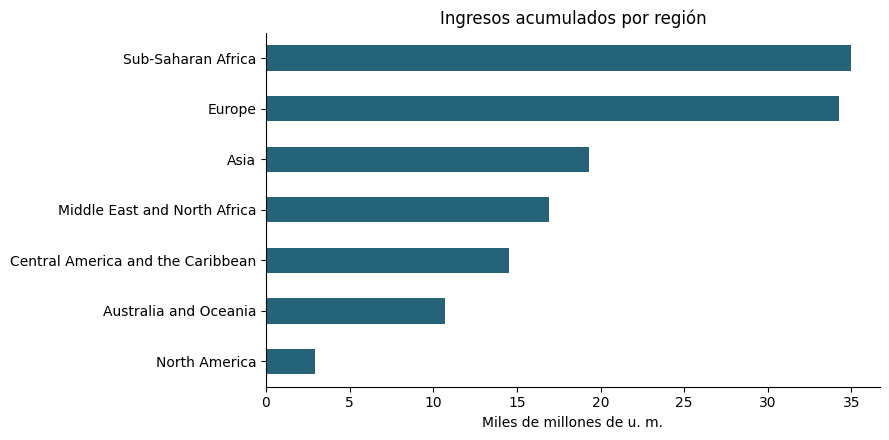

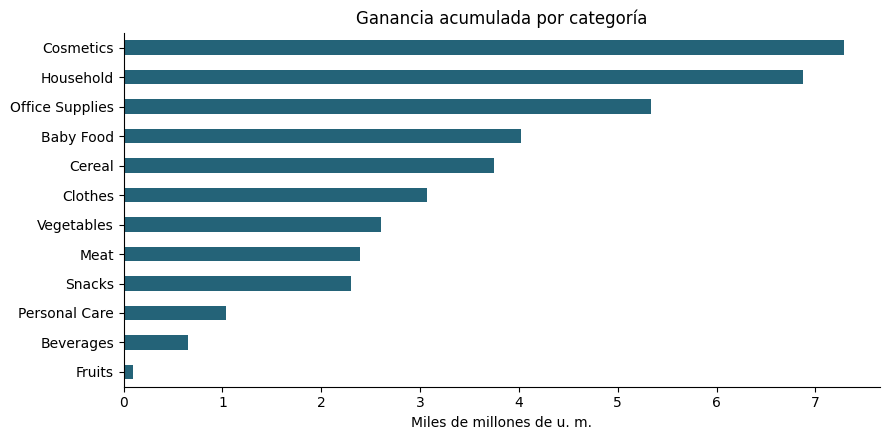

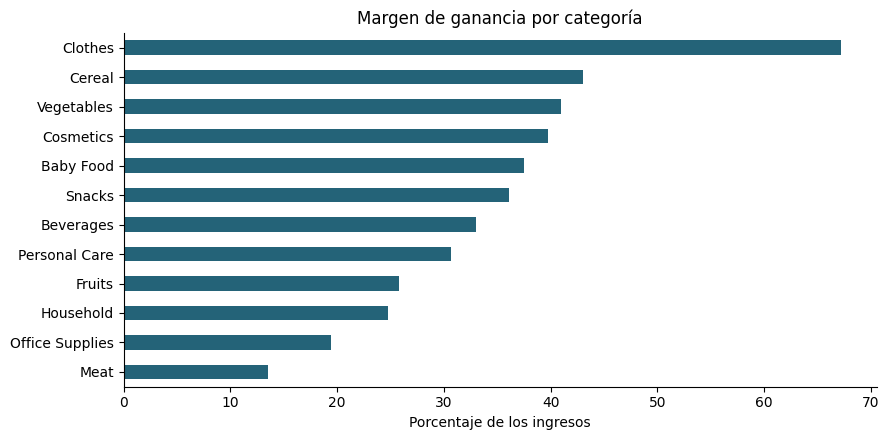

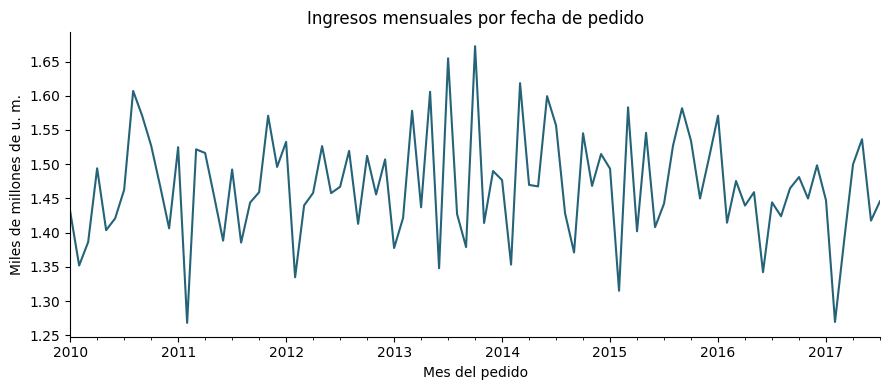

Periodo: 2010-01-01 00:00:00 2017-07-28 00:00:00
Ingresos: 133606673066.41 Ganancia: 39409123729.61
Filtros: 55 15395
Resultados en: /content/resultados_pia


In [ ]:
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
def barras(serie, nombre, titulo, eje):
    ax = serie.sort_values().plot.barh(figsize=(9, 4.5), color='#246378')
    ax.set(title=titulo, xlabel=eje, ylabel='')
    plt.tight_layout()
    plt.savefig(salida / nombre, dpi=180)
    plt.show()
    plt.close()
barras(regiones['Ingresos']/1e9, 'regiones.png',
       'Ingresos acumulados por región', 'Miles de millones de u. m.')
barras(productos['Ganancia']/1e9, 'productos.png',
       'Ganancia acumulada por categoría', 'Miles de millones de u. m.')
barras(productos['Margen_pct'], 'margen.png',
       'Margen de ganancia por categoría', 'Porcentaje de los ingresos')
ax = (mensual/1e9).plot(figsize=(9, 4), color='#246378')
ax.set(title='Ingresos mensuales por fecha de pedido',
       xlabel='Mes del pedido', ylabel='Miles de millones de u. m.')
plt.tight_layout()
plt.savefig(salida / 'mensual.png', dpi=180)
plt.show()
plt.close()
print('Periodo:', df['Order Date'].min(), df['Order Date'].max())
print('Ingresos:', ingresos.sum(), 'Ganancia:', df['Total Profit'].sum())
print('Filtros:', len(filtro), len(altas))
print('Resultados en:', salida.resolve())



## 10 Hallazgos y conclusiones


In [ ]:
print('Mayor ingreso:', productos['Ingresos'].idxmax())
print('Mayor ganancia:', productos['Ganancia'].idxmax())
print('Mayor margen:', productos['Margen_pct'].idxmax())
print('Más unidades:', productos['Unidades'].idxmax())
print('Margen global (%):', round(df['Total Profit'].sum() / df['Total Revenue'].sum() * 100, 2))
print('Cobertura:', df['Order Date'].min().date(), 'a', df['Order Date'].max().date())


Mayor ingreso: Household
Mayor ganancia: Cosmetics
Mayor margen: Clothes
Más unidades: Office Supplies
Margen global (%): 29.5
Cobertura: 2010-01-01 a 2017-07-28


**Interpretación para el reporte:** Cosmetics lidera la ganancia, Household los ingresos, Office Supplies las unidades y Clothes el margen. Conviene evaluar estas medidas conjuntamente antes de proponer cambios de inventario. Online y Offline tienen ingresos cercanos; sin costos operativos por canal no puede afirmarse cuál es más eficiente.


## 12 Descargar tablas y gráficas
Entrega tablas y graficas en zip


In [ ]:
import shutil
zip_path = shutil.make_archive('resultados_pia', 'zip', salida)
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>